In [1]:
import utils.database as db
from utils import cellmath, cellplot
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

#20, 75, 160

frame = 160
data = db.get_frame(frame, db.get_database_path())
cache = cellmath.create_dbond_vertex_cache(data["directed_bonds"], data["vertices"])

cell_data = data["cells"]
dbonds_data = data["directed_bonds"]
vertices_data = data["vertices"]

Average Area difference (Magnitude) =  11.78


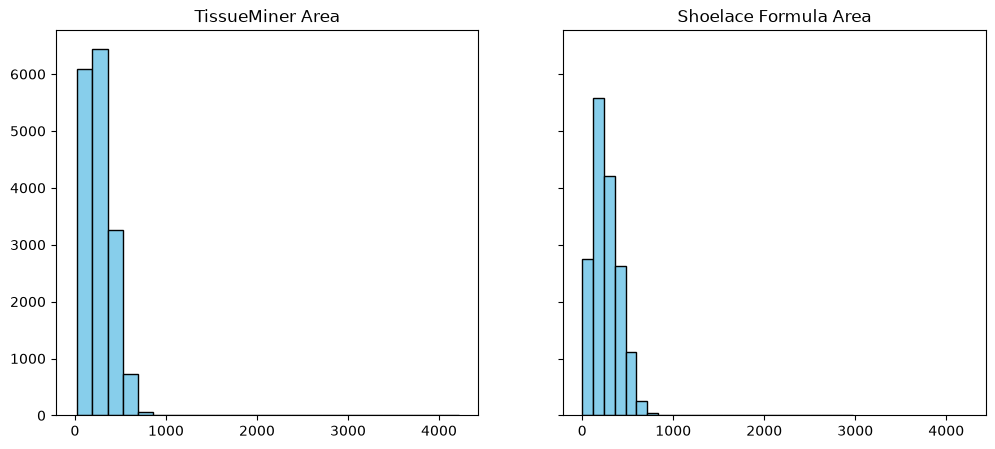

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, sharex=True , sharey=True, figsize=(12, 5))

cleaned_cell_data = cell_data[cell_data["cell_id"] != 10000]

ax1.hist(cleaned_cell_data["area"], bins=25, color="skyblue", edgecolor="black")
ax1.set_title("TissueMiner Area")

shoelace_areas = []
for id in cleaned_cell_data["cell_id"]:
    vList = cellmath.get_cell_vertices(id, cache)
    shoelace_areas.append(cellmath.shoelace_area(vList))


ax2.hist(shoelace_areas, bins=25, color="skyblue", edgecolor="black")
ax2.set_title("Shoelace Formula Area")
    
diff = cleaned_cell_data["area"] - pd.Series(shoelace_areas)

cell_data_area_list  = cleaned_cell_data["area"].tolist()

diff = []
for i, val in enumerate(cell_data_area_list):
    diff.append(shoelace_areas[i] - val)

print("Average Area difference (Magnitude) = ", np.round(np.mean(np.abs(diff)), 3))

Text(0, 0.5, 'Cell Count')

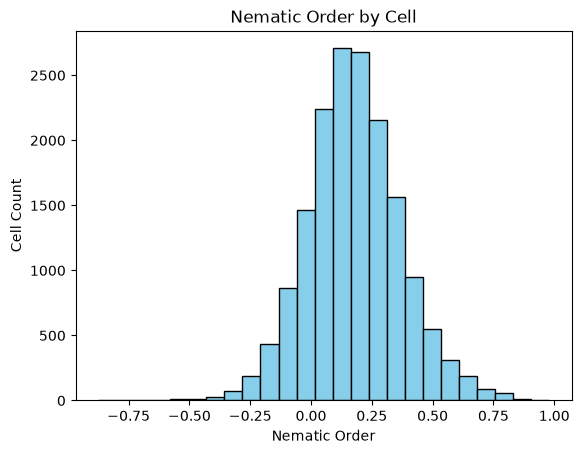

In [3]:
nematic_orders = []
for id in cleaned_cell_data["cell_id"]:
    vList = cellmath.get_cell_vertices(id, cache)
    real, imaginary = cellmath.calc_order(vList, 2)
    nematic_orders.append(real)

plt.hist(nematic_orders, bins=25, color="skyblue", edgecolor="black")
plt.title("Nematic Order by Cell")
plt.xlabel("Nematic Order")
plt.ylabel("Cell Count")

Cell with id: 62349 has less than 3 vertices
Cell with id: 62204 has less than 3 vertices
Cell with id: 62375 has less than 3 vertices
Cell with id: 61873 has less than 3 vertices
Cell with id: 62260 has less than 3 vertices
Cell with id: 62445 has less than 3 vertices
Cell with id: 60616 has less than 3 vertices
Cell with id: 61313 has less than 3 vertices
Cell with id: 62466 has less than 3 vertices
Cell with id: 62480 has less than 3 vertices
Cell with id: 62349 has less than 3 vertices
Cell with id: 62204 has less than 3 vertices
Cell with id: 62375 has less than 3 vertices
Cell with id: 61873 has less than 3 vertices
Cell with id: 62260 has less than 3 vertices
Cell with id: 62445 has less than 3 vertices
Cell with id: 60616 has less than 3 vertices
Cell with id: 61313 has less than 3 vertices
Cell with id: 62466 has less than 3 vertices
Cell with id: 62480 has less than 3 vertices
Cell with id: 62349 has less than 3 vertices
Cell with id: 62204 has less than 3 vertices
Cell with 

Text(0.5, 1.0, 'Cells in Frame: 160, Shaded by aspect ratio')

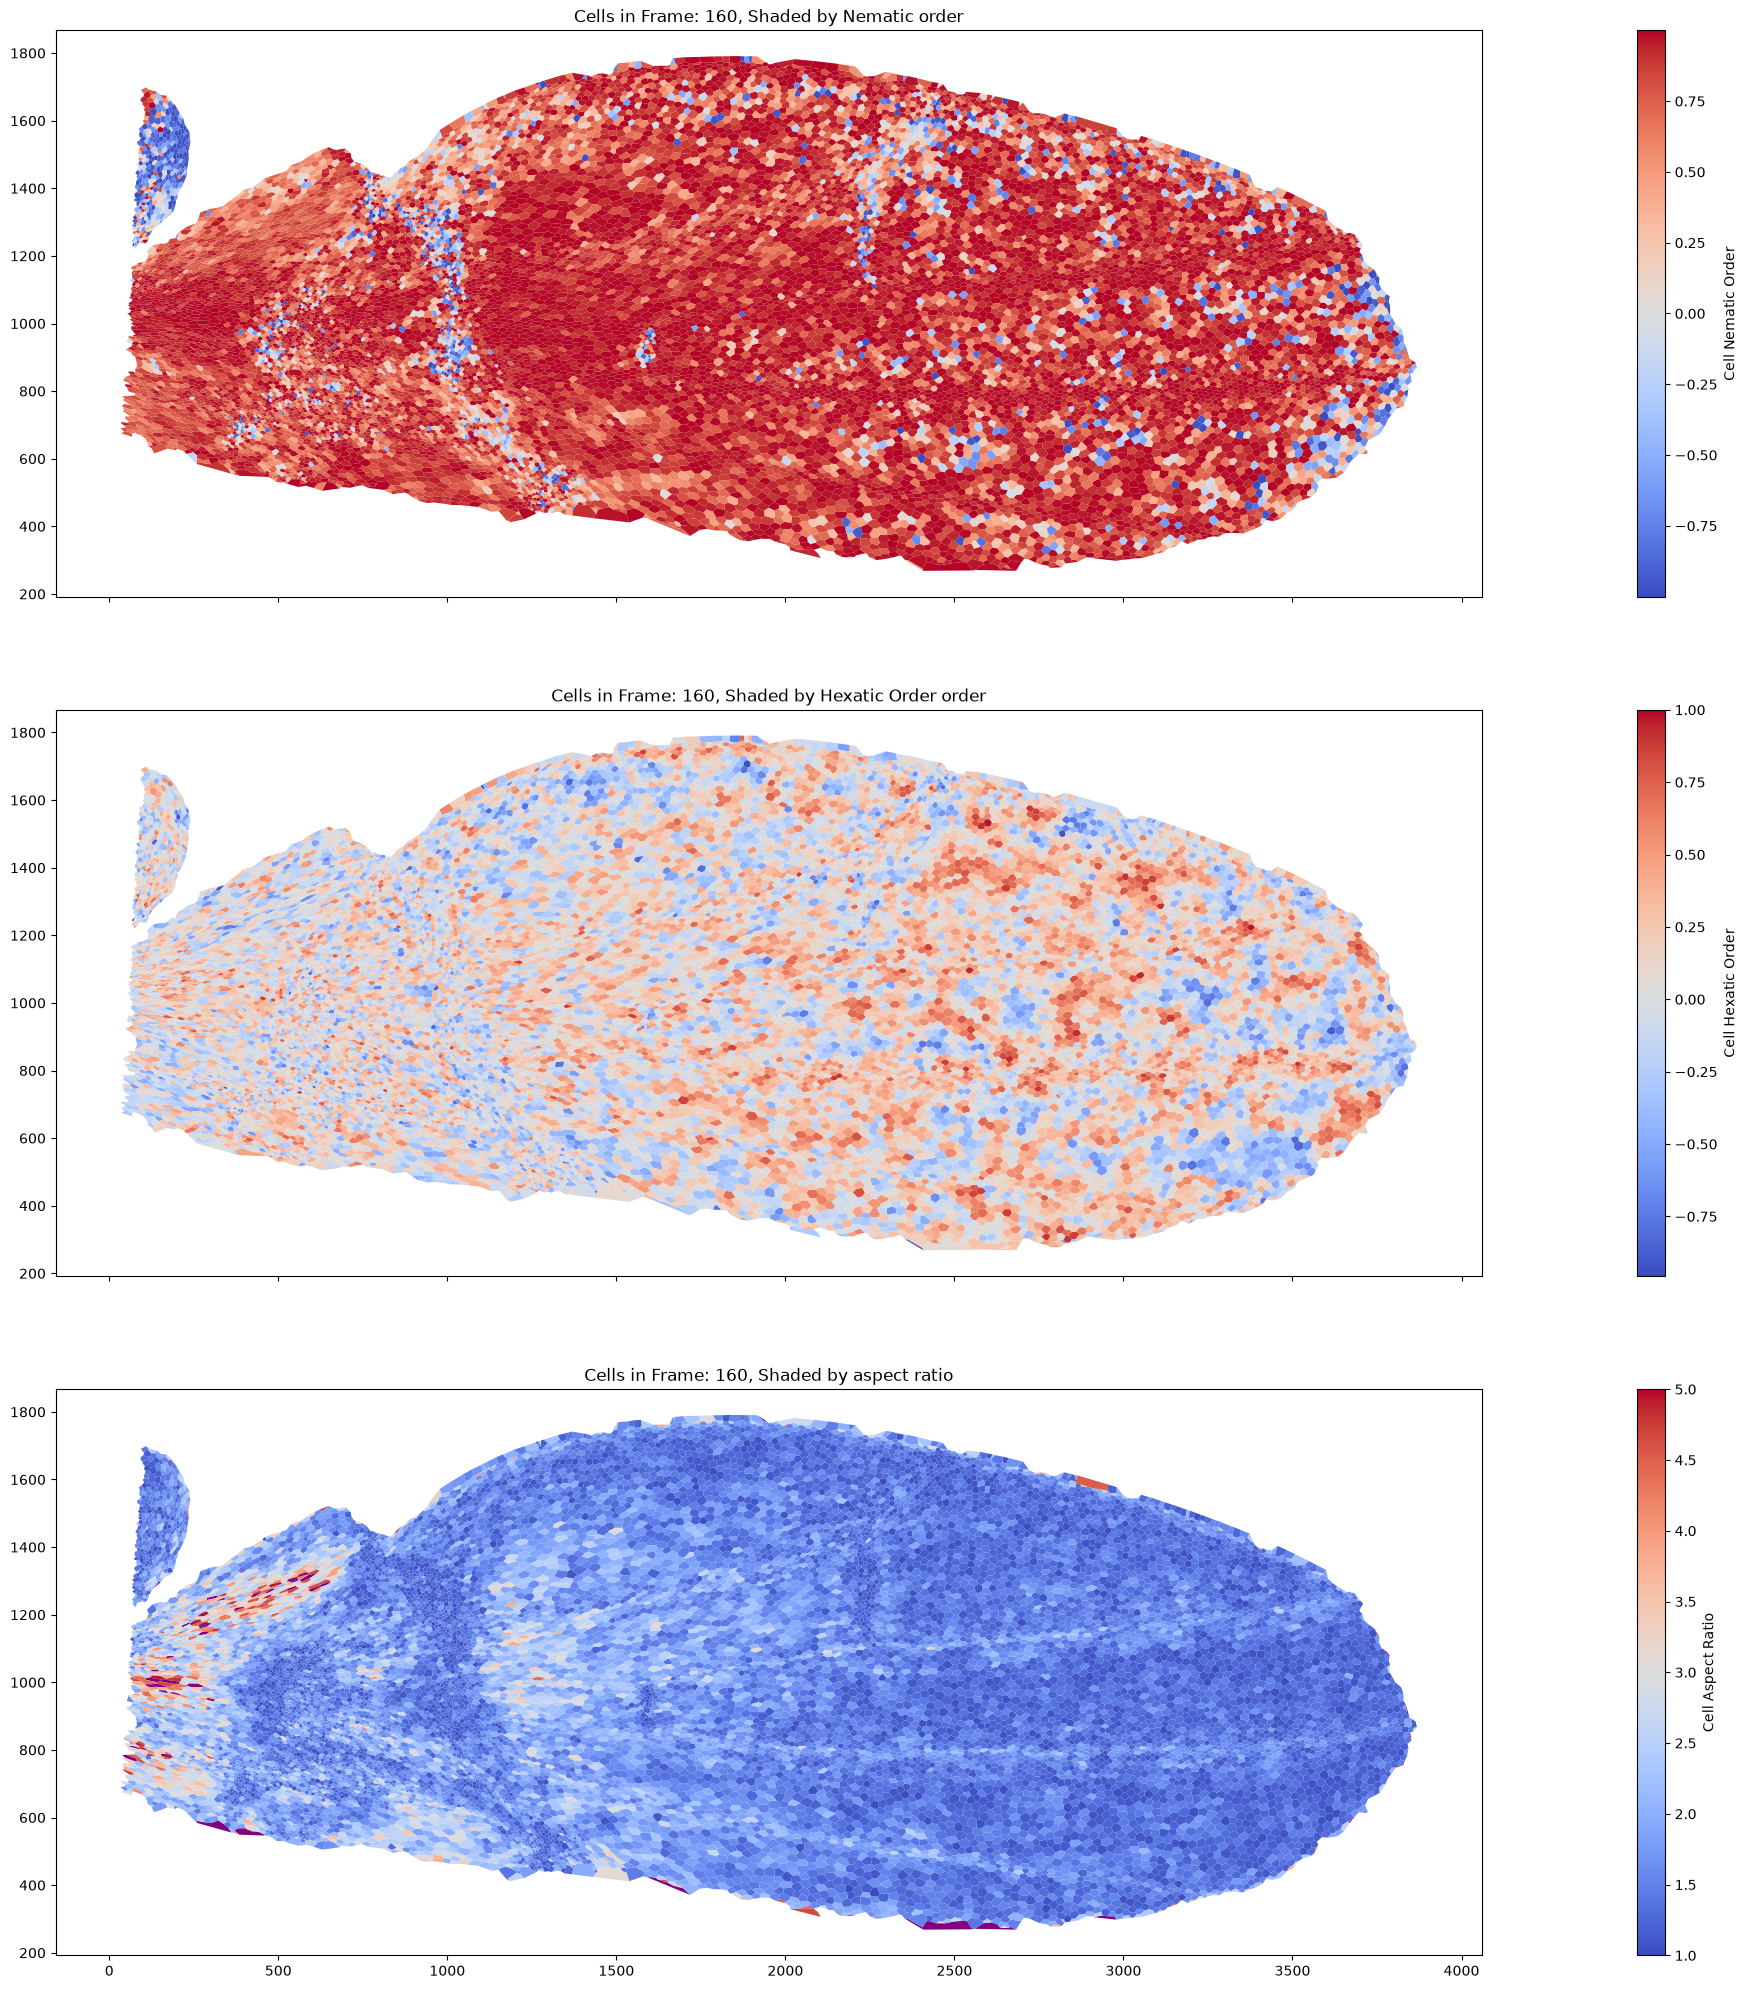

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(50, 25), sharex=True, sharey=True)

n_order_dict = cellmath.nematic_order_dict(cleaned_cell_data, cache, False)
hexatic_order_dict = cellmath.order_dict(cleaned_cell_data, cache, 6, False) 
aspect_ratio_dict = cellmath.aspect_ratio_dict(cleaned_cell_data, cache)

# local_hexatic_order_dict = cellmath.local_hexatic_order_dict(cleaned_cell_data, cache, dbonds_data)

cellplot.draw_cell_boundaries(
    ax1,
    fig,
    "Cell Nematic Order",
    frame,
    cleaned_cell_data["cell_id"].tolist(),
    hue_vals=n_order_dict,
    omega_max=max(n_order_dict.values()),
    omega_min=min(n_order_dict.values()),
    border_width=0.001,
)

ax1.set_title(f"Cells in Frame: {frame}, Shaded by Nematic order")

cellplot.draw_cell_boundaries(
    ax2,
    fig,
    "Cell Hexatic Order",
    frame,
    cleaned_cell_data["cell_id"].tolist(),
    hue_vals=hexatic_order_dict,
    omega_max=max(hexatic_order_dict.values()),
    omega_min=min(hexatic_order_dict.values()),
    border_width=0.001,
)

ax2.set_title(f"Cells in Frame: {frame}, Shaded by Hexatic Order order")

cellplot.draw_cell_boundaries(
    ax3,
    fig,
    "Cell Aspect Ratio",
    frame,
    cleaned_cell_data["cell_id"].tolist(),
    aspect_ratio_dict,
    omega_max=3,
    omega_min=1,
    border_width=0.001,
)

ax3.set_title(f"Cells in Frame: {frame}, Shaded by aspect ratio")

Cell with id: 62349 has less than 3 vertices
Cell with id: 62204 has less than 3 vertices
Cell with id: 62375 has less than 3 vertices
Cell with id: 61873 has less than 3 vertices
Cell with id: 62260 has less than 3 vertices
Cell with id: 62445 has less than 3 vertices
Cell with id: 60616 has less than 3 vertices
Cell with id: 61313 has less than 3 vertices
Cell with id: 62466 has less than 3 vertices
Cell with id: 62480 has less than 3 vertices
Cell with id: 62349 has less than 3 vertices
Cell with id: 62204 has less than 3 vertices
Cell with id: 62375 has less than 3 vertices
Cell with id: 61873 has less than 3 vertices
Cell with id: 62260 has less than 3 vertices
Cell with id: 62445 has less than 3 vertices
Cell with id: 60616 has less than 3 vertices
Cell with id: 61313 has less than 3 vertices
Cell with id: 62466 has less than 3 vertices
Cell with id: 62480 has less than 3 vertices


Text(0.5, 1.0, 'Cells in Frame: 160, Shaded by Nematic order')

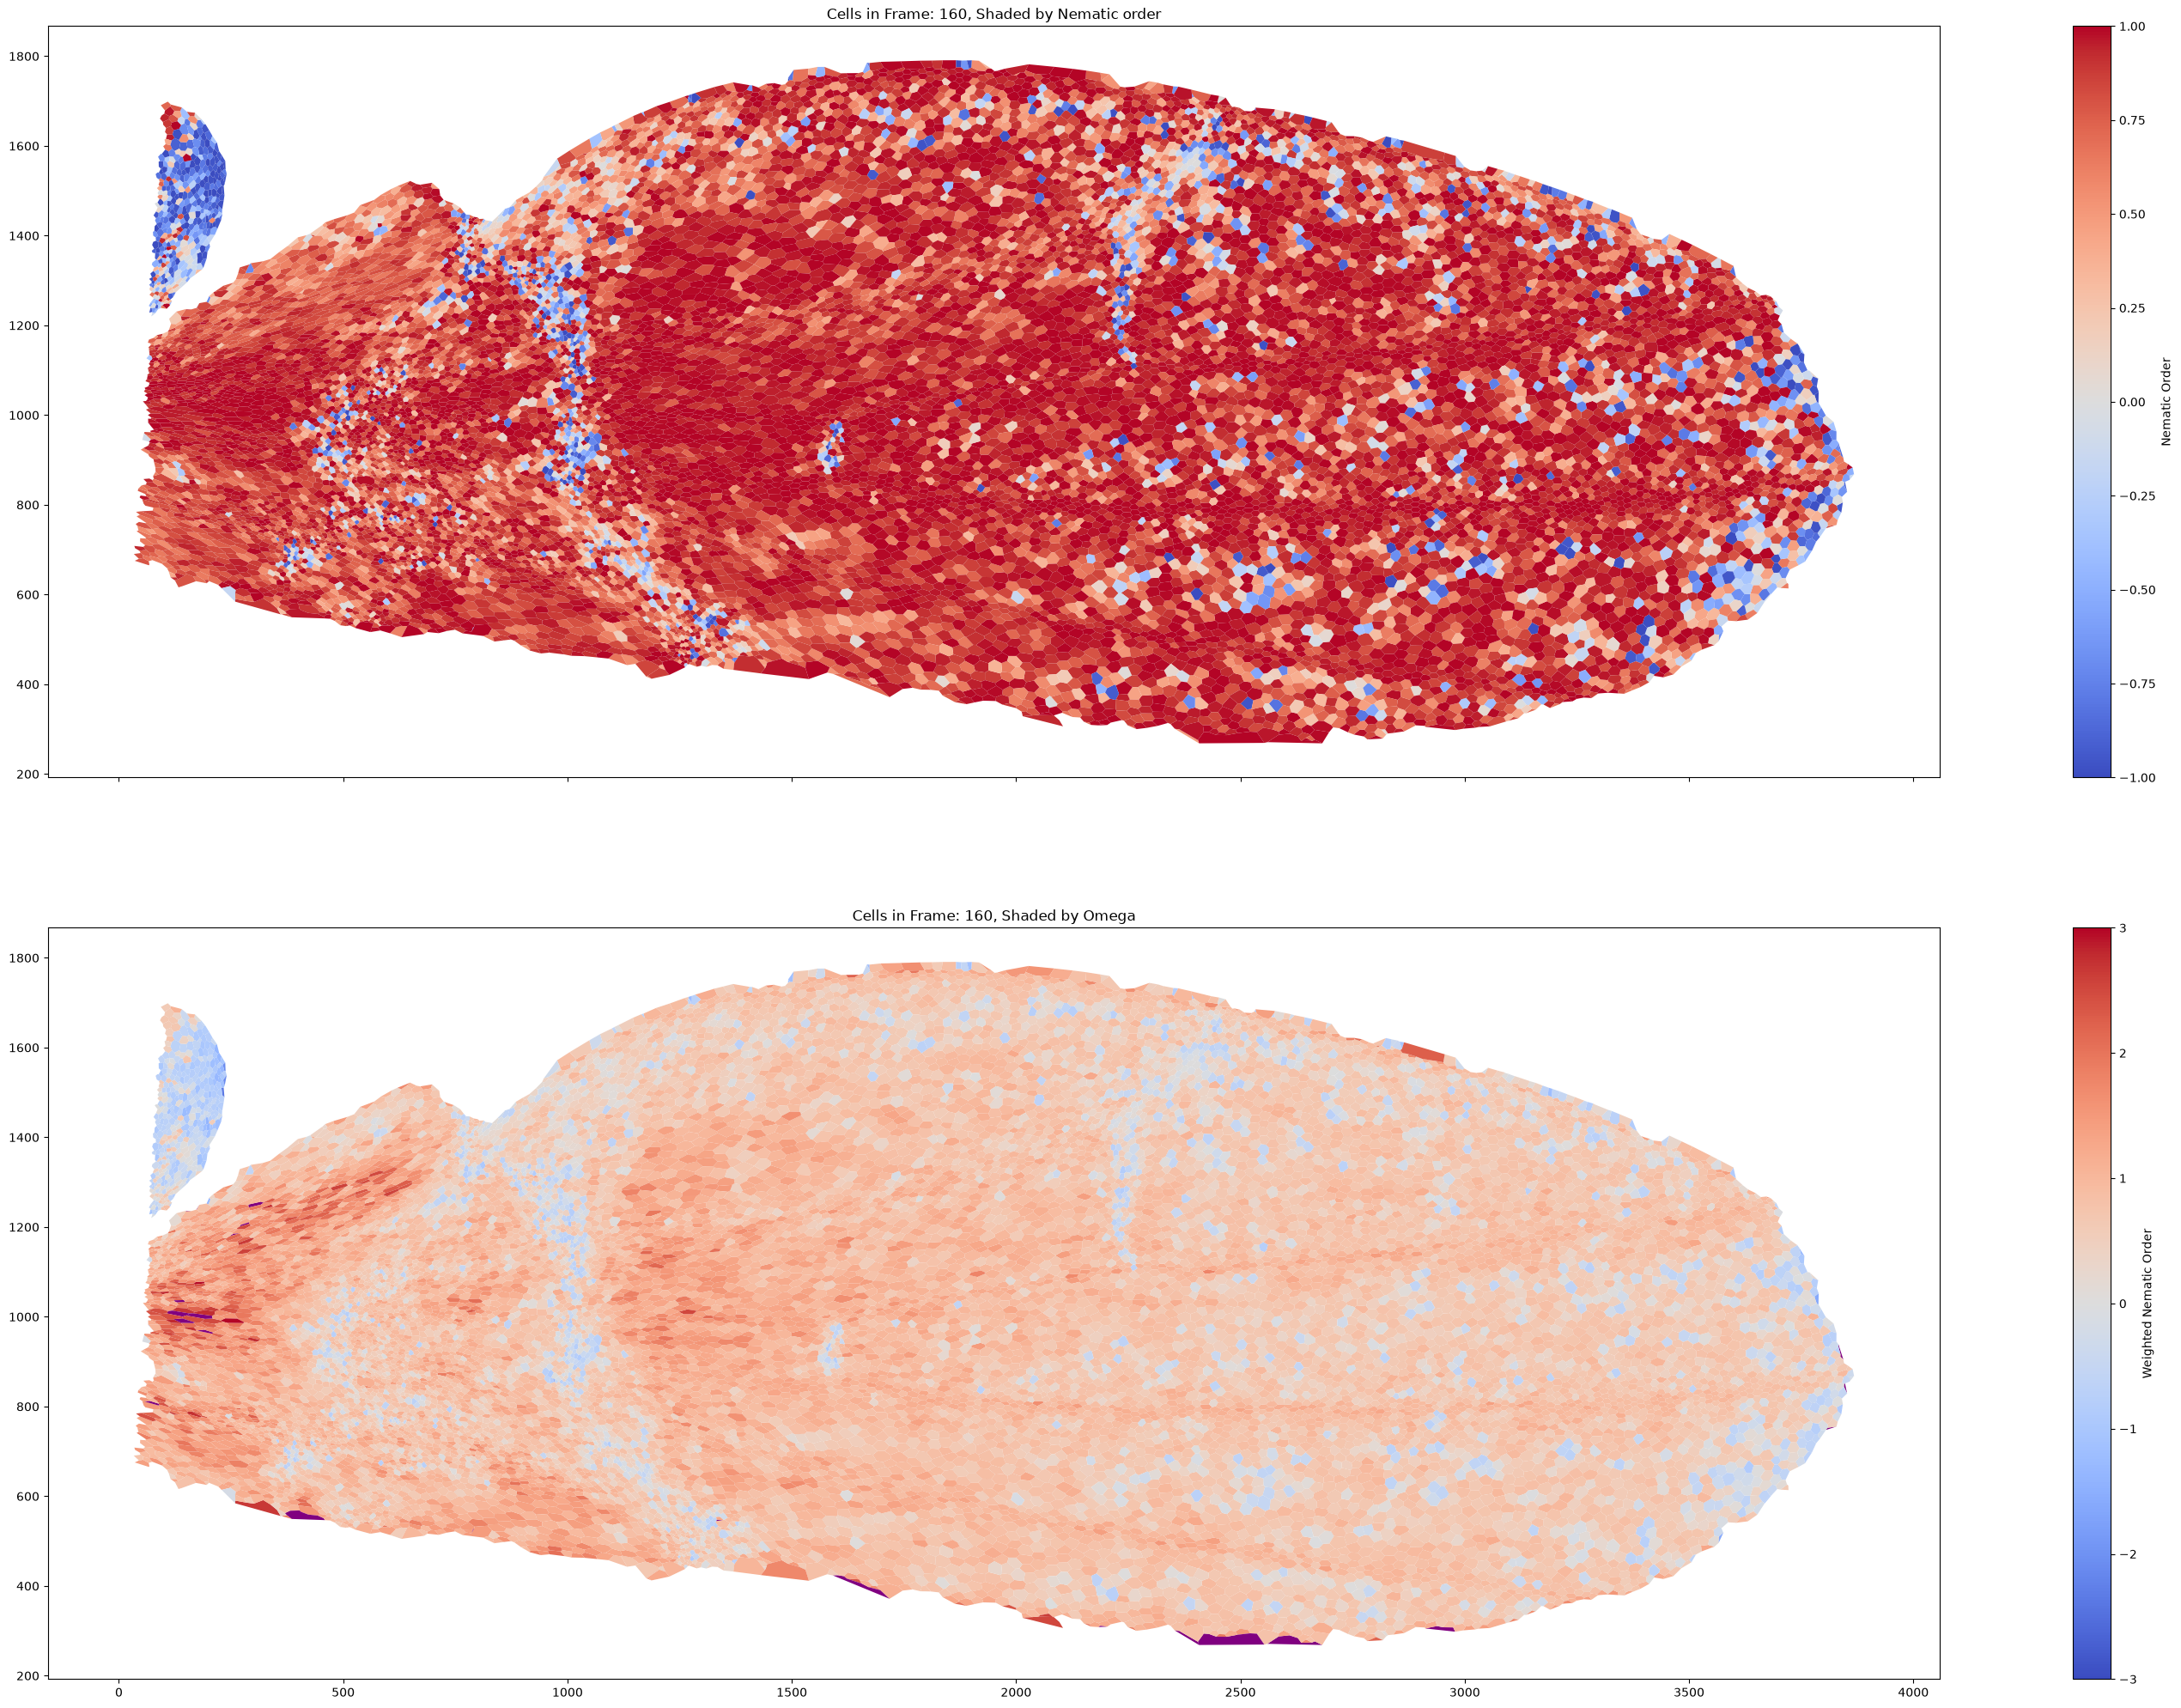

In [10]:

def weighted_order_dict(nematic_order_dict, aspect_ratio_dict):
    avg_aspect_ratio = np.mean(list(aspect_ratio_dict.values()))
    weighted_order_dict = dict()

    for cell_id, n_order in nematic_order_dict.items():
        weighted_order_dict[cell_id] = (
            aspect_ratio_dict[cell_id] * n_order / avg_aspect_ratio
        )

    return weighted_order_dict

w_order_dict = weighted_order_dict(n_order_dict, aspect_ratio_dict)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(50, 25), sharex=True, sharey=True)

cellplot.draw_cell_boundaries(
    ax2,
    fig,
    "Weighted Nematic Order",
    frame,
    cleaned_cell_data["cell_id"].tolist(),
    w_order_dict,
    omega_max=3,
    omega_min=-3,
    border_width=0.001
)

ax2.set_title(f"Cells in Frame: {frame}, Shaded by Omega")


cellplot.draw_cell_boundaries(
    ax1,
    fig,
    "Nematic Order",
    frame,
    cleaned_cell_data["cell_id"].tolist(),
    n_order_dict,
    omega_max=1,
    omega_min=-1,
    border_width=0.001
)

ax1.set_title(f"Cells in Frame: {frame}, Shaded by Nematic order")


Cell with id: 62349 has less than 3 vertices
Cell with id: 62204 has less than 3 vertices
Cell with id: 62375 has less than 3 vertices
Cell with id: 61873 has less than 3 vertices
Cell with id: 62260 has less than 3 vertices
Cell with id: 62445 has less than 3 vertices
Cell with id: 60616 has less than 3 vertices
Cell with id: 61313 has less than 3 vertices
Cell with id: 62466 has less than 3 vertices
Cell with id: 62480 has less than 3 vertices


Text(0.5, 1.0, 'Cells in Frame: 160, Shaded by Area (pixels squared)')

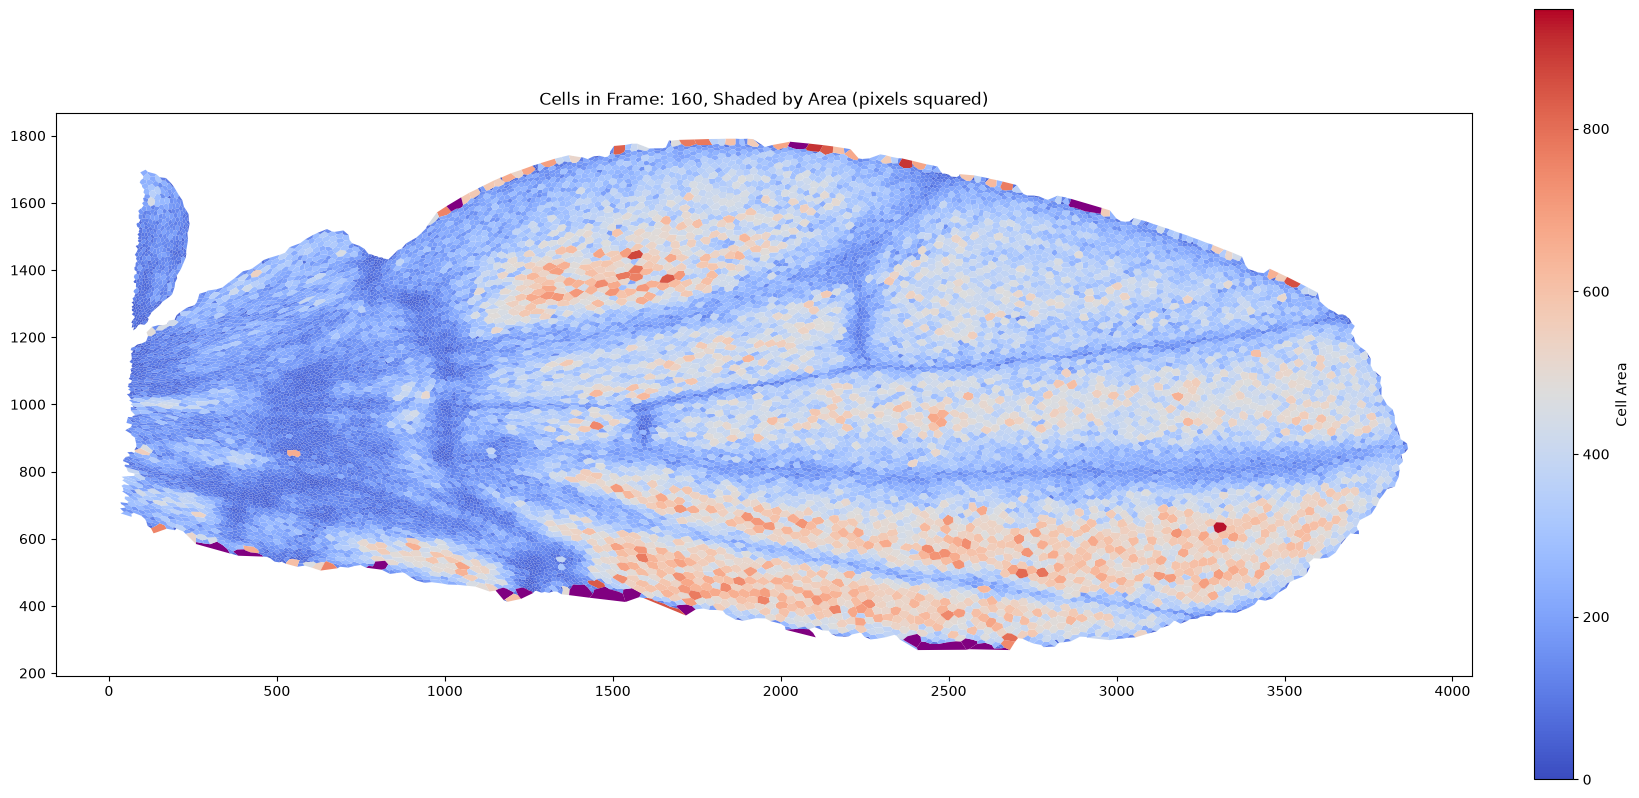

In [16]:
fig, ax = plt.subplots(figsize=(20,10))

shoelace_area_dict = dict(zip(cleaned_cell_data["cell_id"], shoelace_areas))

cellplot.draw_cell_boundaries(
    ax,
    fig,
    "Cell Area",
    frame,
    cleaned_cell_data["cell_id"].tolist(),
    shoelace_area_dict,
    omega_max=np.percentile(list(shoelace_area_dict.values()), 99.9),
    omega_min=min(shoelace_area_dict.values()),
    border_width=0.001
)

ax.set_title(f"Cells in Frame: {frame}, Shaded by Area (pixels squared)")

In [34]:
print(np.mean(list(n_order_dict.values())))
print(np.mean(list(hexatic_order_dict.values())))
np.mean(list(aspect_ratio_dict.values()))

0.6689060122596923
0.076234927809164


np.float64(1.727627347624717)

In [35]:
print(np.max(list(hexatic_order_dict.values())))
print(np.max(list(n_order_dict.values())))

print(np.min(list(hexatic_order_dict.values())))
print(np.min(list(n_order_dict.values())))

1.0
0.9999999956860789
-0.9556472301483154
-0.9999997827359335


Text(0, 0.5, 'Cell Count')

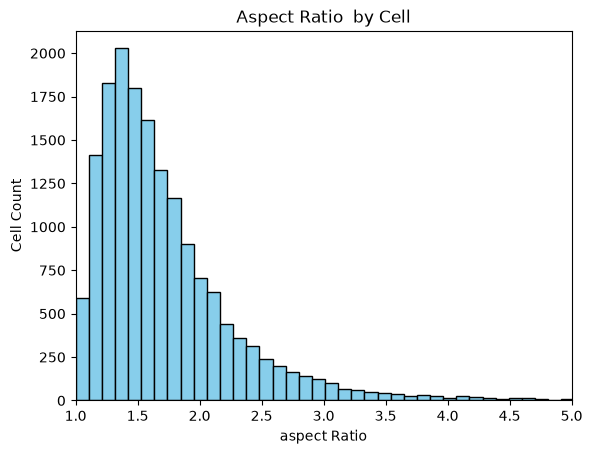

In [41]:

plt.hist(list(aspect_ratio_dict.values()), bins=155, color="skyblue", edgecolor="black")
plt.title("Aspect Ratio  by Cell")
plt.xlim(1,5)
plt.xlabel("aspect Ratio")
plt.ylabel("Cell Count")

TypeError: get_cell_vertices() takes 2 positional arguments but 3 were given

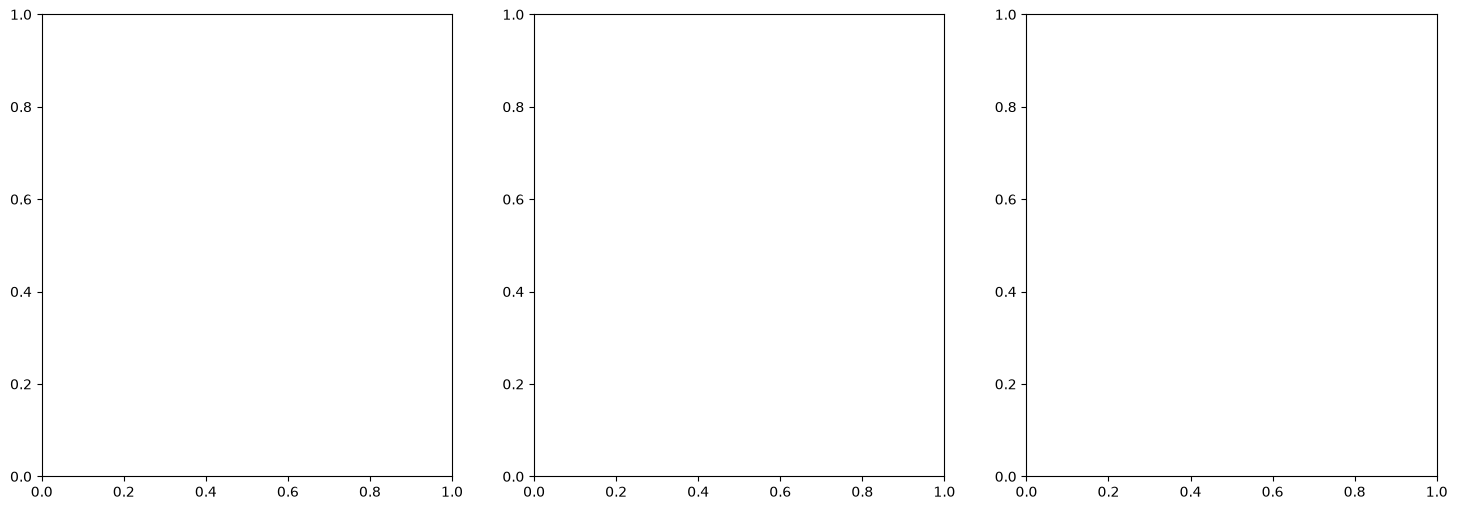

In [36]:
# Find interesting cells
lowest_cell = min(n_order_dict, key=n_order_dict.get)
highest_cell = max(n_order_dict, key=n_order_dict.get)
zero_cell = min(n_order_dict, key=lambda cid: abs(n_order_dict[cid]))

selected_cells = [lowest_cell, zero_cell, highest_cell]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

all_dbonds = dbonds_data
all_vertices = vertices_data

for ax, cell_id in zip(axes, selected_cells):

    # Get cell vertices
    cell_vertices = cellmath.get_cell_vertices(
        cell_id, all_dbonds, all_vertices
    )

    points = np.array([
        [v["x_pos"], v["y_pos"]]
        for v in cell_vertices
    ])

    # Cell center
    center = points.mean(axis=0)

    # Principal axis from covariance matrix
    covariance = np.cov(points, rowvar=False)
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)

    principal_axis = eigenvectors[:, np.argmax(eigenvalues)]

    # Convert principal axis -> phi
    phi = np.arctan2(
        principal_axis[1],
        principal_axis[0]
    )

    # Draw cell
    ax.fill(
        points[:, 0],
        points[:, 1],
        facecolor="lightgray",
        edgecolor="black",
        alpha=0.7
    )

    # Draw orange dot at center
    ax.scatter(
        center[0],
        center[1],
        color="orange",
        s=50,
        zorder=5
    )

    # Draw green principal/nematic axis
    length = np.sqrt(eigenvalues.max()) * 2

    dx = length * np.cos(phi)
    dy = length * np.sin(phi)

    ax.plot(
        [center[0] - dx, center[0] + dx],
        [center[1] - dy, center[1] + dy],
        color="green",
        linewidth=3
    )
    ax.set_title(
        f"Cell {cell_id}\n"
        f"Nematic = {n_order_dict[cell_id]:.3f}\n"
        f"φ = {np.degrees(phi):.1f}°"
    )

    ax.set_aspect("equal")

plt.tight_layout()
plt.show()